# Pontia - Entrega final de la asignatura **Large Language Models**
---

**Autor:** Jaime Lozano Cillero

# 0. Preparación del entorno

In [1]:
from dataclasses import dataclass, field
from datetime import datetime
import json
import time
import requests
from typing import Any, Literal
from pydantic import BaseModel, Field
from pypdf import PdfReader

from langchain_core.messages import (
    AIMessage,
    BaseMessage,
    HumanMessage,
    SystemMessage,
    ToolMessage,
    trim_messages,
)
from langchain_core.runnables import RunnableConfig
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langchain_openai import OpenAIEmbeddings
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.vectorstores import InMemoryVectorStore

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import START, MessagesState, StateGraph
from langgraph.prebuilt import tools_condition

import pandas as pd
import matplotlib.pyplot as plt

import getpass
import os
from dotenv import load_dotenv
from pathlib import Path

load_dotenv()

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")

GENERATION_MODEL = os.getenv("OPENAI_GENERATION_MODEL", "gpt-4.1-mini")
EMBEDDING_MODEL = os.getenv("OPENAI_EMBEDDING_MODEL", "text-embedding-3-small")

PDF_PATH = Path("../../data/raw/TENERIFE.pdf")

RAG_K = 3

MAX_TOOL_RETRIES = 3

# Retraso en segundos
STREAMING_DELAY_PER_CHAR = 0.003

print("Modelo generativo:", GENERATION_MODEL)
print("Modelo de embeddings:", EMBEDDING_MODEL)
print("PDF:", PDF_PATH.resolve())



Modelo generativo: gpt-4.1-mini
Modelo de embeddings: text-embedding-3-small
PDF: C:\Users\Jaime\Documents\Pontia\modulo-06-llms\entrega-final\pontia-llms-entrega-final\data\raw\TENERIFE.pdf


## 0.1 Observabilidad y Logging de Herramientas

Persistencia a nivel de sesión/notebook. Permite registrar ejecuciones, recibir callbacks en tiempo real y mostrar tablas o resúmenes de intentos.

In [2]:
@dataclass
class ToolExecution:
    """Registro observable de una llamada real a herramienta con soporte de reintentos."""

    name: str
    arguments: dict[str, Any]
    ok: bool
    output: Any
    elapsed_seconds: float
    attempt: int = 1
    max_retries: int = 1
    timestamp: datetime = field(default_factory=datetime.now)

    def to_report(self) -> str:
        """Devuelve un informe legible del intento individual."""
        status_label = "✅ OK" if self.ok else "❌ ERROR"
        formatted_args = json.dumps(self.arguments, ensure_ascii=False)
        formatted_output = (
            json.dumps(self.output, ensure_ascii=False, indent=2)
            if isinstance(self.output, (dict, list))
            else str(self.output)
        )

        return (
            f"┌─ [TOOL EXECUTION] {self.name} ({status_label}) ────────────────────────\n"
            f"│ Timestamp : {self.timestamp.strftime('%Y-%m-%d %H:%M:%S')}\n"
            f"│ Intento   : {self.attempt}/{self.max_retries}\n"
            f"│ Duración  : {self.elapsed_seconds:.4f}s\n"
            f"│ Argumentos: {formatted_args}\n"
            f"│ Resultado :\n"
            + "\n".join(f"│   {line}" for line in formatted_output.splitlines())
            + "\n└─────────────────────────────────────────────────────────────"
        )


class ToolExecutionLogger:
    """Buffer de auditoría que registra cada intento individual de ejecución."""

    def __init__(self, verbose: bool = True) -> None:
        self.verbose = verbose
        self.history: list[ToolExecution] = []

    def log(self, execution: ToolExecution) -> None:
        """Registra un intento en el historial."""
        self.history.append(execution)
        if self.verbose:
            print(execution.to_report())

    def print_history(self, only_failures: bool = False) -> None:
        """Imprime la tabla de intentos detallando el número de reintento."""
        if not self.history:
            print("\n[HISTORIAL] No hay llamadas registradas en la sesión.")
            return

        total = len(self.history)
        failures_count = sum(1 for e in self.history if not e.ok)
        successes_count = total - failures_count

        records = (
            [e for e in self.history if not e.ok] if only_failures else self.history
        )

        if only_failures and not records:
            print(
                f"\n[HISTORIAL] ✅ Sin errores: todos los intentos ({total}) fueron exitosos."
            )
            return

        if only_failures:
            error_rate = (failures_count / total) * 100
            header_title = (
                f"HISTORIAL DE FALLOS [FILTRO: SOLO ERRORES] "
                f"({len(records)} de {total} intentos | Tasa de fallo: {error_rate:.1f}%)"
            )
        else:
            header_title = (
                f"HISTORIAL GLOBAL DE INTENTOS "
                f"(Total: {total} | Éxitos: {successes_count} | Fallos: {failures_count})"
            )

        formatted_rows: list[str] = []
        for i, exec_item in enumerate(records, start=1):
            status = "OK" if exec_item.ok else "ERROR"
            time_str = f"{exec_item.elapsed_seconds:.3f}s"
            hora_str = exec_item.timestamp.strftime("%H:%M:%S")
            attempt_str = f"{exec_item.attempt}/{exec_item.max_retries}"

            if (
                only_failures
                and isinstance(exec_item.output, dict)
                and "message" in exec_item.output
            ):
                detail = f"[{exec_item.output.get('error_type', 'Error')}] {exec_item.output['message']}"
            else:
                detail = json.dumps(exec_item.arguments, ensure_ascii=False)

            formatted_rows.append(
                f"{i:<4} {hora_str:<9} {exec_item.name:<20} {attempt_str:<9} {status:<8} {time_str:<10} {detail}"
            )

        table_width = max(
            [len(header_title), 85] + [len(row) for row in formatted_rows]
        )
        sep_main = "=" * table_width
        sep_sub = "-" * table_width

        print("\n" + sep_main)
        print(header_title)
        print(sep_main)
        print(
            f"{'#':<4} {'HORA':<9} {'HERRAMIENTA':<20} {'INTENTO':<9} {'ESTADO':<8} {'TIEMPO':<10} {'ARGS / DETALLE'}"
        )
        print(sep_sub)
        for row in formatted_rows:
            print(row)
        print(sep_main + "\n")
        
    def clear(self) -> None:
            """Limpia el historial de la sesión."""
            self.history.clear()


session_tool_logger = ToolExecutionLogger(verbose=False)

# 1. RAG

## 1.1 Carga de datos

Se usará el fichero suministrado `TENERIFE.pdf`.

El objetivo es que el contenido acabe convertido en objetos `Document`, que tienen dos partes:

- `page_content`: el texto del documento.
- `metadata`: información adicional, como fuente, página, ruta, fecha, categoría, etc.

In [3]:
if not PDF_PATH.exists():
    raise FileNotFoundError(f"No se encontró el PDF en {PDF_PATH.resolve()}")

reader = PdfReader(str(PDF_PATH))

docs = [
    Document(
        page_content=page.extract_text().strip(),
        metadata={
            "source": PDF_PATH.name,
            "page": page_number,  # Base 1: 1 a 25
            "total_pages": len(reader.pages),
        },
    )
    for page_number, page in enumerate(reader.pages, start=1) # Base 1: 1 a 25
]

print(f"Páginas cargadas: {len(docs)} | Primera página (Base 1): {docs[0]}")

Páginas cargadas: 25 | Primera página (Base 1): page_content='TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo 
dirección Plaza Weyler - ubicación –; ir hacia el Parque García Sanabria - 
ubicación -; y bajar de nuevo hacia Plaza de España pasando por la Plaza del 
Príncipe - ubicación). 
- Volver de nuevo a por el coche. 
- Ir hacia la playa de Las Teresitas (ubicación). 
Los puntos de interés sugeridos son estos: 
o Parque Marítimo César Manrique [vídeo - ubicación] 
Conjunto de piscinas naturales.' metadata={'source': 'TENERIFE.pdf', 'page': 1, 'total_p

## 1.1 Análisis de mejor estrategia de chunking

Dentro de la implementación sencilla de chunking que se utilizará, deseamos usar los mejores parámetros para obtener la mejor recuperación de información relevante en las consultas que se realizarán.

Para evaluar diferentes escenarios se confecciona un conjunto de validación con estas características:
- Se plantean preguntas que se pueden responder con la información contenida en el PDF.
- Se hacen preguntas de distintas categorías, desde los detalles a cuestiones generales: micro_detalle, micro_gastronomia, macro_itinerario, macro_naturaleza, etc.
- Se preguntan cuestiones de todas las páginas.
- Se proponen keywords para cada pregunta que se considera deberían aparecer en los chunks recuperados del RAG.
- Se indica la página donde aparece la información que responde la pregunta.

Posteriormente se implementa un pequeño framework que evalúa las métricas clave siguientes en función de distintos escenarios según el tamaño del chunk elegido y el número de chunks recuperados en la consulta.

### Métricas clave en la evaluación del RAG

- **Page Hit Rate@k**: Proporción de consultas donde al menos un fragmento recuperado pertenece a la página esperada.

- **MRR@k (Mean Reciprocal Rank)**: Mide la efectividad del recuperador para colocar el primer fragmento de información relevante en una posición alta de la lista de resultados.

- **Keyword Coverage@k**: Proporción de keywords esperadas presentes dentro del texto de los chunks recuperados.

- **Strict Hit Rate@k**: exige que el fragmento pertenezca a la página esperada y además contenga las entidades clave (keywords) necesarias para responder.


Iniciando simulación comparativa de Chunking con InMemoryVectorStore...

✓ Pequeño (500 / 80)        -> 51 chunks en 23.97s
✓ Medio-Bajo (700 / 120)    -> 40 chunks en 24.06s
✓ Medio (900 / 180)         -> 35 chunks en 23.70s
✓ Grande (1200 / 250)       -> 29 chunks en 24.09s

 COMPARATIVA MATRICIAL POR MÉTRICA Y PROFUNDIDAD (k)

▶ PAGE HIT RATE @ k:
k                                   1       2       3       4       5       6
Configuración Chunking Chunks                                                
Pequeño (500 / 80)     51      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Medio-Bajo (700 / 120) 40      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Medio (900 / 180)      35      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
Grande (1200 / 250)    29      1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
------------------------------------------------------------------------------

▶ STRICT HIT RATE @ k (Página + Keywords):
k                                   1       2       3  

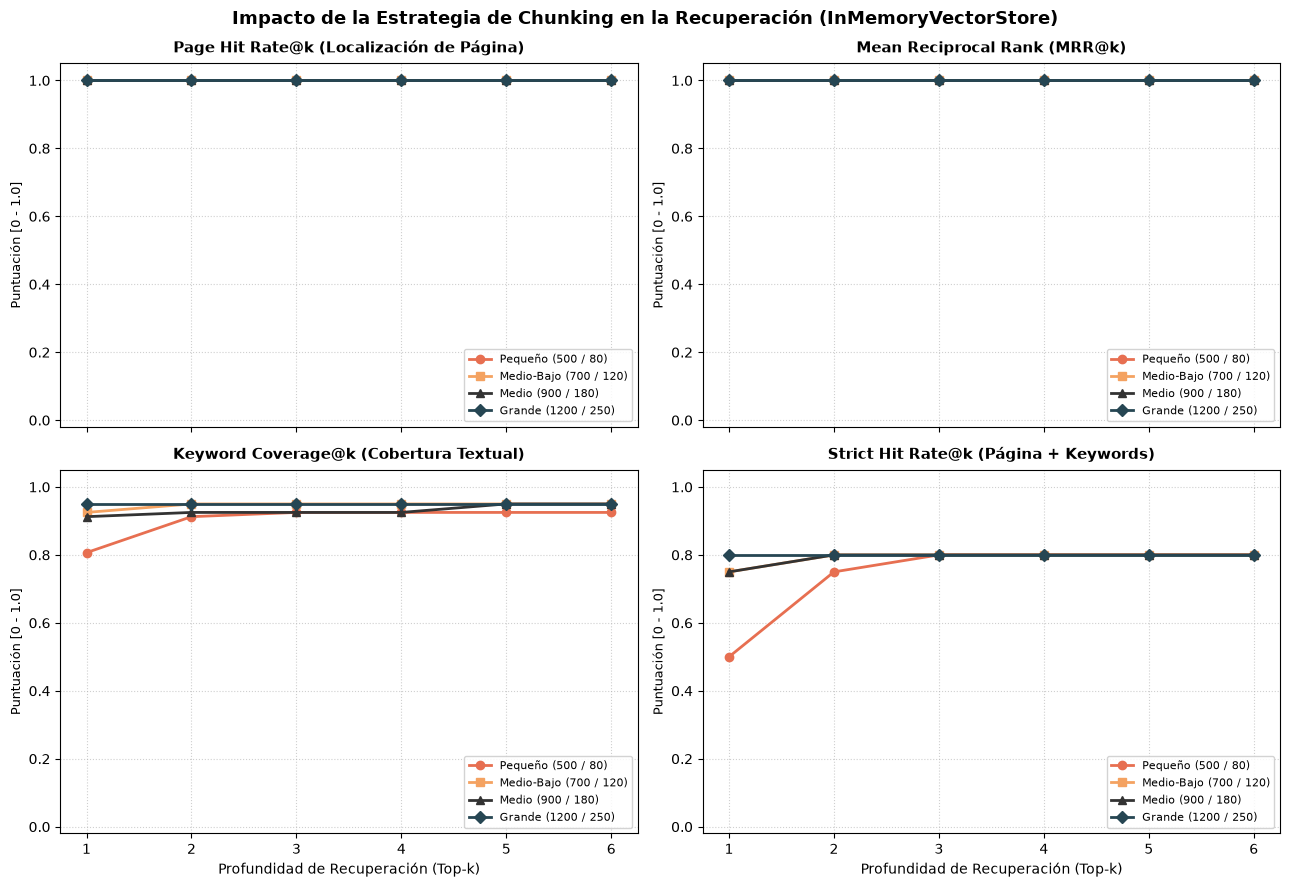

In [4]:
# ---------------------------------------------------------------------------
# Separadores estructurales y Escenarios de Simulación
# ---------------------------------------------------------------------------
CUSTOM_SEPARATORS = [
    "\n\n",   # Secciones mayores
    "\n• ",   # Puntos de interés y municipios
    "\n▪ ",   # Sub-recomendaciones (restaurantes, locales)
    "\n- ",   # Pasos de rutas o itinerarios
    "\n o ",  # Listados secundarios
    "\n",     # Saltos de línea
    ". ",     # Frases
    " ",      # Palabras
]

SCENARIOS = [
    {"name": "Pequeño (500 / 80)", "chunk_size": 500, "chunk_overlap": 80},
    {"name": "Medio-Bajo (700 / 120)", "chunk_size": 700, "chunk_overlap": 120},
    {"name": "Medio (900 / 180)", "chunk_size": 900, "chunk_overlap": 180},
    {"name": "Grande (1200 / 250)", "chunk_size": 1200, "chunk_overlap": 250},
]

# ---------------------------------------------------------------------------
# Conjunto de evaluación
# ---------------------------------------------------------------------------
EVAL_DATASET = [
    # -----------------------------------------------------------------------
    # BLOQUE 1: ZONA METROPOLITANA Y LA LAGUNA
    # -----------------------------------------------------------------------
    {
        "query": "¿Cuál es la ruta a pie recomendada para visitar Santa Cruz de Tenerife y dónde se aconseja aparcar el coche?",
        "expected_page": 1,
        "category": "macro_itinerario",
        "keywords": ["parque marítimo", "avenida marítima", "plaza de españa"],
    },
    {
        "query": "¿Qué curiosidad histórica presenta el reloj del torreón de la Iglesia de la Concepción en La Laguna?",
        "expected_page": 3,
        "category": "micro_detalle",
        "keywords": ["iglesia de la concepción", "iiii", "números romanos"],
    },
    {
        "query": "¿Qué plato específico y qué restaurante recomienda para comer al callejear hacia la Plaza del Adelantado en La Laguna?",
        "expected_page": 4,
        "category": "micro_gastronomia",
        "keywords": ["la cueva de casiano", "batata", "almogrote"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 2: PARQUE RURAL DE ANAGA Y SUS COSTAS
    # -----------------------------------------------------------------------
    {
        "query": "¿Por qué destaca el Parque Rural de Anaga a nivel natural y cuál es el itinerario diario sugerido para recorrerlo?",
        "expected_page": 5,
        "category": "macro_naturaleza",
        "keywords": ["reserva de la biosfera", "endemismos", "playa de benijo", "mirador de la jardina"],
    },
    {
        "query": "¿En qué mirador de Anaga se puede tomar la foto típica en un pasillo superfrondoso de vegetación?",
        "expected_page": 6,
        "category": "micro_detalle",
        "keywords": ["pico del inglés", "pasillo", "frondoso"],
    },
    {
        "query": "¿Cómo se llega a la Playa de Benijo y qué indicación da sobre la valla que corta el acceso?",
        "expected_page": 8,
        "category": "micro_detalle",
        "keywords": ["playa de benijo", "arena negra", "valla", "atardeceres"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 3: VALLE DE LA OROTAVA Y SUS PLAYAS
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué récord Guinness ostenta La Orotava y qué singularidad geográfica comparte con el Teide?",
        "expected_page": 9,
        "category": "macro_patrimonio",
        "keywords": ["récord guinness", "alfombra", "desnivel", "3.718"],
    },
    {
        "query": "¿En qué punto de la Calle de la Carrera de La Orotava se puede comprar gofio tradicional?",
        "expected_page": 9,
        "category": "micro_detalle",
        "keywords": ["molino de chano", "gofio", "carrera"],
    },
    {
        "query": "¿Qué precauciones sobre las mareas y el mar se deben tener al bajar a las playas de Los Patos y El Ancón?",
        "expected_page": 10,
        "category": "micro_seguridad",
        "keywords": ["los patos", "ancón", "difícil acceso", "marea esté baja"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 4: PUERTO DE LA CRUZ E ISLA BAJA
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué recorrido a pie se sugiere en el Puerto de la Cruz desde la explanada del muelle hasta la Plaza del Charco?",
        "expected_page": 11,
        "category": "macro_itinerario",
        "keywords": ["explanada del muelle", "lago de martiánez", "calle quintana", "plaza del charco"],
    },
    {
        "query": "¿Qué localidades y carreteras componen la ruta típica de domingo por la comarca de la Isla Baja?",
        "expected_page": 12,
        "category": "macro_itinerario",
        "keywords": ["isla baja", "icod de los vinos", "garachico", "tf5", "tf42"],
    },
    {
        "query": "¿Junto a qué fortaleza están las Piscinas Naturales del Caletón en Garachico y qué pizzería se recomienda allí?",
        "expected_page": 12,
        "category": "micro_detalle",
        "keywords": ["castillo de san miguel", "caletón", "chuso", "rugantino"],
    },
    {
        "query": "¿Qué pastelería se recomienda visitar al aparcar cerca de la Plaza de los Remedios en Buenavista del Norte?",
        "expected_page": 13,
        "category": "micro_gastronomia",
        "keywords": ["buenavista", "plaza de los remedios", "el aderno", "dulcito"],
    },
    {
        "query": "¿Cómo se accede actualmente a la Punta de Teno y qué superproducción cinematográfica grabó allí su inicio?",
        "expected_page": 14,
        "category": "micro_curiosidad",
        "keywords": ["punta de teno", "línea 369", "titsa", "fast & furious 6"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 5: PARQUE NACIONAL DEL TEIDE
    # -----------------------------------------------------------------------
    {
        "query": "¿Cuál es la subida recomendada al Teide en coche y qué mirador destaca por las tonalidades de su roca y el mar de nubes?",
        "expected_page": 15,
        "category": "macro_paisaje",
        "keywords": ["tf24", "la esperanza", "la tarta", "mar de nubes"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 6: ZONA SUR (ADEJE, MASCA Y ENTRETENIMIENTO)
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué áreas diferenciadas tiene el Monkey Beach Club sobre la Playa de Troya y cuál es idónea para cócteles al atardecer?",
        "expected_page": 17,
        "category": "micro_ocio",
        "keywords": ["playa de troya", "monkey beach club", "bésamemucho", "kong", "cielo"],
    },
    {
        "query": "¿Qué récords mundiales ostenta el parque acuático Siam Park en Costa Adeje?",
        "expected_page": 21,
        "category": "macro_atraccion",
        "keywords": ["siam park", "ola artificial", "río lento", "tailandesa"],
    },
    {
        "query": "¿Desde qué municipio se accede al caserío de Masca y qué trámite previo se exige para hacer la bajada de su barranco?",
        "expected_page": 22,
        "category": "micro_logistica",
        "keywords": ["santiago del teide", "barranco de masca", "reservar", "antelación", "pateada"],
    },
    # -----------------------------------------------------------------------
    # BLOQUE 7: GASTRONOMÍA LOCAL AUTÉNTICA (GUACHINCHES Y BOCADILLOS)
    # -----------------------------------------------------------------------
    {
        "query": "¿Qué particularidades hacen genuino al Guachinche El Cubano en Santa Úrsula y qué únicas tres bebidas ofrecen?",
        "expected_page": 24,
        "category": "micro_gastronomia",
        "keywords": ["guachinche el cubano", "camino de tierra", "no hay carta", "vino", "seven up", "agua"],
    },
    {
        "query": "¿Qué arepas y entrante recomienda pedir en la Arepera La Carajita situada entre La Orotava y Puerto de la Cruz?",
        "expected_page": 25,
        "category": "micro_gastronomia",
        "keywords": ["la carajita", "la fogalera", "reina pepiada", "cachapitas"],
    },
]


# ---------------------------------------------------------------------------
# Construcción del Vector Store con InMemoryVectorStore
# ---------------------------------------------------------------------------
def build_vector_store_for_scenario(
    docs: list[Document],
    chunk_size: int,
    chunk_overlap: int,
    embeddings: OpenAIEmbeddings,
) -> tuple[InMemoryVectorStore, int]:
    """Genera los chunks y crea una instancia limpia de InMemoryVectorStore."""
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=CUSTOM_SEPARATORS,
        add_start_index=True,
    )
    split_chunks = splitter.split_documents(docs)

    for idx, chunk in enumerate(split_chunks, start=1):
        chunk.metadata["chunk_id"] = idx

    # InMemoryVectorStore gestiona los vectores en memoria RAM efímera
    vector_store = InMemoryVectorStore.from_documents(split_chunks, embeddings)
    return vector_store, len(split_chunks)

# ---------------------------------------------------------------------------
# Evaluación de Métricas de Recuperación
# ---------------------------------------------------------------------------
def evaluate_scenario_retrieval(
    vector_store: InMemoryVectorStore,
    dataset: list[dict],
    k_values: tuple[int, ...] = (1, 2, 3, 4, 5, 6),
) -> list[dict]:
    """Calcula Page Hit Rate, MRR, Keyword Coverage y Strict Hit Rate."""
    total_queries = len(dataset)
    metrics_summary = []

    for k in k_values:
        page_hits = 0
        strict_hits = 0
        total_keyword_coverage = 0.0
        reciprocal_ranks = []

        for item in dataset:
            query = item["query"]
            expected_page = int(item["expected_page"])
            keywords = [kw.lower() for kw in item.get("keywords", [])]

            retrieved = vector_store.similarity_search(query, k=k)

            retrieved_pages = [
                int(doc.metadata.get("page"))
                for doc in retrieved
                if doc.metadata.get("page") is not None
            ]
            all_content = " ".join(doc.page_content.lower() for doc in retrieved)

            # 1. Page Hit Rate y MRR
            if expected_page in retrieved_pages:
                page_hits += 1
                rank = retrieved_pages.index(expected_page) + 1
                reciprocal_ranks.append(1.0 / rank)
            else:
                reciprocal_ranks.append(0.0)

            # 2. Keyword Coverage
            if keywords:
                found_kws = sum(1 for kw in keywords if kw in all_content)
                coverage = found_kws / len(keywords)
                total_keyword_coverage += coverage
                all_kws_present = (coverage == 1.0)
            else:
                total_keyword_coverage += 1.0
                all_kws_present = True

            # 3. Strict Hit Rate
            if (expected_page in retrieved_pages) and all_kws_present:
                strict_hits += 1

        metrics_summary.append({
            "k": k,
            "Page Hit Rate": page_hits / total_queries,
            "MRR": sum(reciprocal_ranks) / total_queries,
            "Keyword Coverage": total_keyword_coverage / total_queries,
            "Strict Hit Rate": strict_hits / total_queries,
        })

    return metrics_summary




# ---------------------------------------------------------------------------
# Ejecución del Experimento Multiescenario
# ---------------------------------------------------------------------------
embeddings = OpenAIEmbeddings(model=EMBEDDING_MODEL)
all_results = []

print("\nIniciando simulación comparativa de Chunking con InMemoryVectorStore...\n")

for sc in SCENARIOS:
    t0 = time.perf_counter()
    name = sc["name"]
    c_size = sc["chunk_size"]
    c_overlap = sc["chunk_overlap"]

    vs, total_chunks = build_vector_store_for_scenario(
        docs=docs,
        chunk_size=c_size,
        chunk_overlap=c_overlap,
        embeddings=embeddings,
    )

    metrics = evaluate_scenario_retrieval(vs, EVAL_DATASET, k_values=(1, 2, 3, 4, 5, 6))
    elapsed = time.perf_counter() - t0

    print(f"✓ {name:25} -> {total_chunks:2} chunks en {elapsed:.2f}s")

    for row in metrics:
        row["Scenario"] = name
        row["chunk_size"] = c_size
        row["chunk_overlap"] = c_overlap
        row["total_chunks"] = total_chunks
        all_results.append(row)

df_experiments = pd.DataFrame(all_results)

# ---------------------------------------------------------------------------
# Visualización de Tablas de Datos
# ---------------------------------------------------------------------------

def print_separator(title: str, width: int = 78):
    print("\n" + "=" * width)
    print(f" {title}")
    print("=" * width)


# A) TABLAS MATRICIALES COMPARATIVAS (Escenario vs k para cada métrica)
# ---------------------------------------------------------------------------
print_separator("COMPARATIVA MATRICIAL POR MÉTRICA Y PROFUNDIDAD (k)")

metrics_display = [
    ("Page Hit Rate", "PAGE HIT RATE @ k"),
    ("Strict Hit Rate", "STRICT HIT RATE @ k (Página + Keywords)"),
    ("MRR", "MEAN RECIPROCAL RANK (MRR @ k)"),
    ("Keyword Coverage", "KEYWORD COVERAGE @ k"),
]

for col_metric, metric_title in metrics_display:
    print(f"\n▶ {metric_title}:")
    
    # Creamos tabla pivote: Filas = Escenario (con chunks), Columnas = k
    pivot_table = df_experiments.pivot_table(
        index=["Scenario", "total_chunks"],
        columns="k",
        values=col_metric,
        sort=False,
    )
    
    # Renombramos el índice para mayor claridad en el print
    pivot_table.index.names = ["Configuración Chunking", "Chunks"]
    
    # Formateo a 4 decimales
    formatted_pivot = pivot_table.map(lambda v: f"{v:0.4f}")
    print(formatted_pivot.to_string())
    print("-" * 78)


# B) TABLA COMPLETA DESGLOSADA POR ESCENARIO
# ---------------------------------------------------------------------------
print_separator("DESGLOSE COMPLETO DE RESULTADOS POR ESCENARIO")

cols_to_show = [
    "k",
    "Page Hit Rate",
    "MRR",
    "Keyword Coverage",
    "Strict Hit Rate",
]

for scenario_name, group in df_experiments.groupby("Scenario", sort=False):
    chunks_count = group["total_chunks"].iloc[0]
    c_size = group["chunk_size"].iloc[0]
    c_overlap = group["chunk_overlap"].iloc[0]
    
    print(f"\n📦 ESCENARIO: {scenario_name}")
    print(f"   Parámetros: chunk_size={c_size} | chunk_overlap={c_overlap} | Total Chunks={chunks_count}")
    print("-" * 72)
    
    df_sub = group[cols_to_show].copy()
    # Formateo visual numérico
    df_sub["Page Hit Rate"] = df_sub["Page Hit Rate"].map(lambda v: f"{v:0.4f}")
    df_sub["MRR"] = df_sub["MRR"].map(lambda v: f"{v:0.4f}")
    df_sub["Keyword Coverage"] = df_sub["Keyword Coverage"].map(lambda v: f"{v:0.4f}")
    df_sub["Strict Hit Rate"] = df_sub["Strict Hit Rate"].map(lambda v: f"{v:0.4f}")
    
    print(df_sub.to_string(index=False))


# C) RESUMEN EJECUTIVO EN PORCENTAJE (Para memoria / informe en Markdown)
# ---------------------------------------------------------------------------
print_separator("TABLA RESUMEN EJECUTIVO (Puntos de corte k=1, k=2, k=4)")

df_k_eval = df_experiments[df_experiments["k"].isin([1, 2, 4])].copy()

# Preparamos una tabla horizontal clara
resumen = df_k_eval.pivot_table(
    index="Scenario",
    columns="k",
    values=["Page Hit Rate", "Strict Hit Rate", "Keyword Coverage", "MRR"],
    sort=False,
)

# Mostramos en porcentaje para lectura ágil
resumen_pct = resumen.map(lambda v: f"{v * 100:5.1f}%")
print(resumen_pct.to_string())

palette = {
    "Pequeño (500 / 80)": "#e76f51",
    "Medio-Bajo (700 / 120)": "#f4a261",
    "Recomendado (900 / 180)": "#2a9d8f",
    "Grande (1200 / 250)": "#264653",
}
markers = ["o", "s", "^", "D"]

metrics_to_plot = [
    ("Page Hit Rate", "Page Hit Rate@k (Localización de Página)"),
    ("MRR", "Mean Reciprocal Rank (MRR@k)"),
    ("Keyword Coverage", "Keyword Coverage@k (Cobertura Textual)"),
    ("Strict Hit Rate", "Strict Hit Rate@k (Página + Keywords)"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
axes = axes.flatten()

k_vals = sorted(df_experiments["k"].unique())

for idx, (col_name, title) in enumerate(metrics_to_plot):
    ax = axes[idx]
    
    for (scenario_name, df_sc), marker in zip(df_experiments.groupby("Scenario", sort=False), markers):
        color = palette.get(scenario_name, "#333333")
        ax.plot(
            df_sc["k"],
            df_sc[col_name],
            marker=marker,
            linewidth=2,
            markersize=6,
            label=scenario_name,
            color=color,
        )

    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.set_ylabel("Puntuación [0 - 1.0]", fontsize=9)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(k_vals)
    ax.grid(True, linestyle=":", alpha=0.6)
    
    if idx in (2, 3):
        ax.set_xlabel("Profundidad de Recuperación (Top-k)", fontsize=10)
    
    ax.legend(loc="lower right", fontsize=8, framealpha=0.85)

plt.suptitle(
    "Impacto de la Estrategia de Chunking en la Recuperación (InMemoryVectorStore)",
    fontsize=13,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

### Conclusión

Cualquier escenario obtiene la mayor puntuación en Page Hit Rate y MRR.

Keyword Converage y Strict Hit Rate muestran que para k=2 y chunks de tamaño medio-bajo (700/120) se obtienen la puntuaciones más altas de la muestra. Es cierto que se mejoran resultados con chunks de tamaño grande (1200/250) pero a costa de recuperar mayor cantidad de caracteres y de llenar la venta de contexto, que es limitada.

*Se elige finalmente la estrategia de recuperar 3 chunks de 700 caracteres con solapamiento de 120 caracteres como compromiso óptimo.*

## 1.2 *Chunking*

In [5]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=700,
    chunk_overlap=120,
    add_start_index=True,
    separators=CUSTOM_SEPARATORS
)

splits = text_splitter.split_documents(docs)

# Añadimos un identificador simple a cada chunk para poder citarlo luego.
for i, doc in enumerate(splits):
    doc.metadata["page"] = i
    doc.metadata["chunk_id"] = i
    doc.metadata["source_name"] = PDF_PATH.name

print("Número de chunks:", len(splits))
print("\nEjemplo de chunk:\n")
print(splits[0].page_content)
print("\nMetadata:", splits[0].metadata)

Número de chunks: 40

Ejemplo de chunk:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE

Metadata: {'source': 'TENERIFE.pdf', 'page': 0, 'total_pages': 25, 'start_index': 0, 'chunk_id': 0, 'source_name': 'TENERIFE.pdf'}


## 1.3 *Embeddings* y *vector store*

El objetivo del RAG es recuperar información relacionada con las consultas variables del usuario. Para ello, necesitamos comparar el signficado de la pregunta con el significado de nuestros textos (chunks) para recuperar los que sean más parecidos. Esos chunks recuperados serán provistos al LLM como contexto de tal manera que lo integre en su respuesta al usuario y dé como resultado una respuesta relevante.

Para poder comparar significados, cada texto será transformado a embedding y se compararán usando una medida de similaridad.

Se usará la clase `InMemoryVectorStore` para la transformación y almacenamiento de los embeddings en memoria.

In [6]:
vector_store = InMemoryVectorStore(embeddings)
document_ids = vector_store.add_documents(splits)

print("Documentos indexados:", len(document_ids))
print("Primeros IDs:", document_ids[:3])

Documentos indexados: 40
Primeros IDs: ['fd1c66cc-d059-46bc-be57-e373ab544e52', 'e4a9d67f-d9e3-4525-bf3e-c233e4c41f6b', '86c82a73-93cc-46a1-b639-315639b51121']


## 1.4 RAG como herramienta

Se implementa como herramienta de *LangChain* con el decorador ``@tool``.

In [7]:
def search_rag(query: str, k: int = RAG_K) -> list[dict[str, Any]]:
    """ Búsqueda de fragmentos relevantes. """

    # similarity_search_with_score recibe 'query' y 'k'
    retrieved_docs = vector_store.similarity_search_with_score(query, k=k)

    if not retrieved_docs:
        return [{"message": f"No se encontró información relevante para '{query}'."}]

    results: list[dict[str, Any]] = []
    for doc, score in retrieved_docs:
        results.append(
            {
                "score": round(float(score), 4),
                "source": doc.metadata.get("source_name", "Guía de Tenerife"),
                "page": doc.metadata.get("page", "desconocido"),
                "chunk_id": doc.metadata.get("chunk_id", "desconocido"),
                "content": doc.page_content.strip(),
            }
        )

    return results

search_rag("Qué sitios me recomiendas cerca de Playa de Las Américas", 3)

[{'score': 0.6169,
  'source': 'TENERIFE.pdf',
  'page': 32,
  'chunk_id': 32,
  'content': '• El Médano / La Tejita \nPlayas tipiquísimas de Tenerife y otra de las estampas de la isla con Montaña Roja al \nfondo. Nota: La Tejita es playa nudista para que lo tengáis en cuenta.  \n \n \n• Los Cristianos \nDe la zona de Los Cristianos que me venga a la mente os recomendaría la Playa de \nLos Cristianos o la Playa de Las Vistas y creo que poco más (la imagen es la Playa de \nLas Vistas).'},
 {'score': 0.5613,
  'source': 'TENERIFE.pdf',
  'page': 14,
  'chunk_id': 14,
  'content': '• Puerto de La Cruz \nEs la zona turística del Norte de Tenerife. De hecho, hace años era el núcleo turístico \nde la isla hasta que empezó a ganar mucho peso el Sur de Tenerife. \n \n \nPara visitar el Puerto de la Cruz, os recomendaría aparcar en la explanada del muelle \ne ir caminando desde el Muelle hasta la Playa Martiánez recorriendo la Calle de \nSanto Domingo, la calle de San Telmo y la avenida de Cris

In [8]:
class SearchTenerifeDocsInput(BaseModel):
    query: str = Field(
        description=(
            "Términos o pregunta para buscar en la guía interna de Tenerife. "
            "Ejemplos: 'qué ver en La Laguna', 'dónde comer en el norte guachinche', "
            "'playas en La Orotava', 'miradores en Anaga', 'rutas y accesos al Teide', "
            "'beach clubs en Costa Adeje', 'bocadillos de pollo'."
        )
    )
    k: int = Field(
        default=RAG_K,
        ge=1,
        le=5,
        description="Número de fragmentos relevantes a recuperar (entre 1 y 5).",
    )


@tool(args_schema=SearchTenerifeDocsInput)
def search_tenerife_docs(query: str, k: int = 4) -> list[dict[str, Any]]:
    """OBLIGATORIO: Búsqueda en la guía personal de Tenerife suministrada para el proyecto.
    Contiene recomendaciones exclusivas de un guía local sobre distintos lugares, beach clubs,
    gastronomía, ocio y logística de desplazamientos.
    DEBES invocarla SIEMPRE que el usuario pida recomendaciones, rutas, playas,
    dónde comer o curiosidades de Tenerife antes de responder.
    """
    
    retrieved_docs = search_rag(query, k=k)

    return retrieved_docs

# 2. Consulta meteorológica como herramienta

Se podrán consultar el estado meteorológico de lugares a través de Geocoding API de Open-Meteo. Se implementa también gestión de errores.

In [9]:
class WeatherInput(BaseModel):
    location: str = Field(
        description=(
            "Nombre del municipio o zona de Tenerife a consultar (ej. 'Puerto de la Cruz', "
            "'San Cristóbal de La Laguna', 'Adeje', 'La Orotava', 'Santa Cruz de Tenerife', 'El Teide'). "
            "Si el usuario pregunta por 'allí', 'en esa playa' o hace referencia al lugar "
            "comentado en el turno anterior, deduce el municipio exacto y colócalo aquí."
        )
    )
    units: Literal["celsius", "fahrenheit"] = Field(
        default="celsius",
        description="Unidad de medida para la temperatura. Por defecto 'celsius'.",
    )

def geocode_location(location: str) -> dict[str, Any]:
    """Obtiene coordenadas para una ubicación usando Open-Meteo Geocoding."""
    response = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": location, "count": 1, "language": "es", "format": "json"},
        timeout=8,
    )
    response.raise_for_status()
    payload = response.json()
    results = payload.get("results") or []

    if not results:
        raise ValueError(f"No se encontraron coordenadas para '{location}'.")

    first = results[0]
    return {
        "name": first.get("name"),
        "country": first.get("country"),
        "latitude": first["latitude"],
        "longitude": first["longitude"],
        "timezone": first.get("timezone"),
    }


# Variable de apoyo para simular caídas de red transitorias en las pruebas
_simulated_network_failures_remaining = 0

@tool(args_schema=WeatherInput)
def get_weather(
    location: str, units: Literal["celsius", "fahrenheit"] = "celsius"
) -> dict[str, Any]:
    """OBLIGATORIO: Consulta el estado meteorológico actual y temperaturas en tiempo real.
    Debes invocarla SIEMPRE que el usuario pregunte por el tiempo, clima, previsión,
    lluvia, viento o temperatura de cualquier lugar de Tenerife o zona mencionada.
    """

    global _simulated_network_failures_remaining

    # Simulación activa de caída de conexión (dispara el mecanismo de reintentos)
    if _simulated_network_failures_remaining > 0:
        _simulated_network_failures_remaining -= 1
        raise requests.exceptions.ConnectionError(
            "Fallo transitorio simulado: timeout de conexión con la API de Open-Meteo."
        )
    
    # Geocodificación con captura de errores de resolución y red
    try:
        place = geocode_location(location)
    except ValueError as val_err:
        return {
            "status": "error",
            "error_type": "LocationNotFound",
            "message": (
                f"No se encontró la ubicación '{location}'. Pide al usuario que "
                "verifique el nombre o indique una población cercana o más conocida."
            ),
        }
    except requests.exceptions.Timeout:
        return {
            "status": "error",
            "error_type": "TimeoutError",
            "message": "El servicio de geocodificación no respondió a tiempo. Inténtalo de nuevo en unos momentos.",
        }
    except requests.exceptions.RequestException as req_err:
        return {
            "status": "error",
            "error_type": "NetworkError",
            "message": f"Error de comunicación con el servicio de geocodificación: {str(req_err)}",
        }

    # Consulta meteorológica con captura de fallos de API y parsing
    temperature_unit = "fahrenheit" if units == "fahrenheit" else "celsius"

    try:       
        response = requests.get(
            "https://api.open-meteo.com/v1/forecast",
            params={
                "latitude": place["latitude"],
                "longitude": place["longitude"],
                "current": "temperature_2m,relative_humidity_2m,wind_speed_10m",
                "temperature_unit": temperature_unit,
                "timezone": "auto",
            },
            timeout=8,
        )
        response.raise_for_status()
        payload = response.json()

        current = payload.get("current") or {}
        units_payload = payload.get("current_units") or {}

        return {
            "status": "success",
            "location": {
                "name": place["name"],
                "country": place.get("country"),
                "latitude": place["latitude"],
                "longitude": place["longitude"],
            },
            "observed_at": current.get("time"),
            "temperature": current.get("temperature_2m"),
            "temperature_unit": units_payload.get("temperature_2m", "°C"),
            "relative_humidity": current.get("relative_humidity_2m"),
            "relative_humidity_unit": units_payload.get("relative_humidity_2m", "%"),
            "wind_speed": current.get("wind_speed_10m"),
            "wind_speed_unit": units_payload.get("wind_speed_10m", "km/h"),
            "provider": "Open-Meteo",
        }

    except requests.exceptions.Timeout:
        return {
            "status": "error",
            "error_type": "TimeoutError",
            "message": f"Tiempo de espera agotado al obtener el pronóstico para {place['name']}.",
        }
    except requests.exceptions.RequestException as req_err:
        return {
            "status": "error",
            "error_type": "WeatherApiError",
            "message": f"Error al consultar la previsión en Open-Meteo: {str(req_err)}",
        }
    except Exception as exc:
        return {
            "status": "error",
            "error_type": "UnexpectedError",
            "message": f"Error inesperado al procesar los datos del clima: {str(exc)}",
        }

# 3. Configuración del modelo

Se implementa un recortador de la ventana de contexto ajustado a una constante prefijada, MAX_HISTORY_TOKENS.

En cuanto a la memoria y la ventana de contexto hay que destacar lo siguiente. `MemorySaver` guarda todo el histórico del hilo, mientras que `trim_messages` actúa como una ventana deslizante dinámica en el nodo de inferencia. La sesión conserva la trazabilidad completa, pero el modelo nunca recibe más tokens de los permitidos.

Al fijar `start_on="human"`, se previene que la poda empiece en un `ToolMessage` suelto, evitando la ruptura del contrato de mensajes de la API.

Para que el proceso sea 100% resiliente a interrupciones se filtran mensajes huérfanos. Si por cualquier corte existe un tool_call sin su ToolMessage, o un ToolMessage sin su llamada, se limpia antes de enviar el prompt con la función `sanitize_message_history`.

In [10]:
# Configuración de límites de tokens
MAX_OUTPUT_TOKENS = 1000
MAX_HISTORY_TOKENS = 2500

tools = [search_tenerife_docs, get_weather]
tools_by_name = {t.name: t for t in tools}

llm = ChatOpenAI(
    model=GENERATION_MODEL,
    temperature=0.2,
    top_p=0.95,
    max_tokens=MAX_OUTPUT_TOKENS,
    streaming=True,
)
llm_with_tools = llm.bind_tools(tools, tool_choice="auto")

# Selección del prompt de sistema
ruta_prompt = Path("../../resources/prompt_guia_turistico_tenerife.txt")

with open(ruta_prompt, "r", encoding="utf-8") as f:
    SYSTEM_PROMPT = f.read()

message_trimmer = trim_messages(
    max_tokens=MAX_HISTORY_TOKENS,
    strategy="last",
    token_counter=llm,
    start_on="human",
    include_system=False,  # El System Prompt se inyecta siempre fresco
)

def get_token_count(messages: list[BaseMessage]) -> int:
    """Calcula el número exacto de tokens usando el tokenizador del modelo."""
    return llm.get_num_tokens_from_messages(messages)

def sanitize_message_history(messages: list[BaseMessage]) -> list[BaseMessage]:
    """Elimina llamadas a herramientas huérfanas (sin ToolMessage asociado)

    o ToolMessages descolgados para garantizar el contrato estricto de OpenAI.
    """
    if not messages:
        return []

    # Recolectamos todos los IDs respondidos por ToolMessages
    responded_tool_ids = {
        m.tool_call_id for m in messages if isinstance(m, ToolMessage)
    }

    sanitized: list[BaseMessage] = []
    for msg in messages:
        if isinstance(msg, AIMessage) and msg.tool_calls:
            # Filtramos solo las tool_calls que realmente tienen un ToolMessage en la lista
            valid_calls = [
                tc for tc in msg.tool_calls if tc["id"] in responded_tool_ids
            ]
            if valid_calls:
                # Conservamos el mensaje con las llamadas validadas
                sanitized.append(
                    AIMessage(
                        content=msg.content,
                        tool_calls=valid_calls,
                        id=msg.id,
                    )
                )
            elif msg.content:
                # Si tenía texto además del tool_call, lo conservamos como texto puro
                sanitized.append(AIMessage(content=msg.content, id=msg.id))
            # Si no tenía contenido y sus tool_calls quedaron huérfanas, se descarta
        else:
            sanitized.append(msg)

    # Garantizar que el último mensaje no sea un AIMessage con tool_calls si no hay ToolMessage
    while sanitized and isinstance(sanitized[-1], AIMessage) and sanitized[-1].tool_calls:
        sanitized.pop()

    return sanitized

def call_model(state: MessagesState):
    """Nodo del modelo con sanitización de estado, control de tokens e inferencia."""
    raw_messages = state["messages"]

    # 1. Poda de tokens del historial acumulado
    trimmed_messages = message_trimmer.invoke(raw_messages)

    # 2. Saneamiento defensivo ante estados incompletos o cortes bruscos
    safe_messages = sanitize_message_history(trimmed_messages)

    tokens_before = get_token_count(raw_messages)
    tokens_after = get_token_count(safe_messages)

    if len(safe_messages) < len(raw_messages):
        print(
            f"[TOKEN CONTROL] Historial ajustado: {len(raw_messages)} -> {len(safe_messages)} msgs | "
            f"Tokens: {tokens_before} -> {tokens_after} (Límite: {MAX_HISTORY_TOKENS})"
        )

    # 3. Ensamblado del prompt final con System Prompt
    full_prompt = [SystemMessage(content=SYSTEM_PROMPT)] + safe_messages

    # Llamada al LLM
    response = llm_with_tools.invoke(full_prompt)

    return {"messages": [response]}

def audited_tools_node(state: MessagesState, config: RunnableConfig | None = None):
    """Nodo que ejecuta herramientas con soporte de reintentos configurables y logging."""
    configurable = (config or {}).get("configurable", {})
    # Parámetros configurables:
    max_retries: int = configurable.get("max_tool_retries", MAX_TOOL_RETRIES)
    retry_delay: float = configurable.get("tool_retry_delay", 0.5)

    last_message = state["messages"][-1]
    outputs: list[ToolMessage] = []

    for tool_call in last_message.tool_calls:
        name = tool_call["name"]
        args = tool_call["args"]
        call_id = tool_call["id"]
        tool_instance = tools_by_name.get(name)

        final_tool_content = ""
        success = False

        for attempt in range(1, max_retries + 1):
            start_time = time.perf_counter()

            try:
                if not tool_instance:
                    raise ValueError(f"Herramienta no registrada: '{name}'")

                result = tool_instance.invoke(args)
                elapsed = time.perf_counter() - start_time

                # Registro del intento exitoso
                execution = ToolExecution(
                    name=name,
                    arguments=args,
                    ok=True,
                    output=result,
                    elapsed_seconds=elapsed,
                    attempt=attempt,
                    max_retries=max_retries,
                )
                session_tool_logger.log(execution)

                # Serialización estructurada para permitir el parseo de citas en streaming
                if isinstance(result, (list, dict)):
                    final_tool_content = json.dumps(result, ensure_ascii=False)
                else:
                    final_tool_content = str(result)
                
                success = True
                break  # Sale del bucle de reintentos tras el éxito

            except Exception as exc:
                elapsed = time.perf_counter() - start_time

                # Registro de cada fallo individual
                execution = ToolExecution(
                    name=name,
                    arguments=args,
                    ok=False,
                    output={"error_type": type(exc).__name__, "message": str(exc)},
                    elapsed_seconds=elapsed,
                    attempt=attempt,
                    max_retries=max_retries,
                )
                session_tool_logger.log(execution)

                # Si aún quedan reintentos disponibles, esperar antes del siguiente
                if attempt < max_retries:
                    if retry_delay > 0:
                        time.sleep(retry_delay)
                else:
                    # Se agotaron todos los reintentos
                    final_tool_content = (
                        f"Error tras {max_retries} intentos ejecutando '{name}': {str(exc)}"
                    )

        outputs.append(
            ToolMessage(
                content=final_tool_content,
                name=name,
                tool_call_id=call_id,
            )
        )

    return {"messages": outputs}

workflow = StateGraph(state_schema=MessagesState)

workflow.add_node("model", call_model)
workflow.add_node("tools", audited_tools_node)  # Usamos nuestro nodo auditado

workflow.add_edge(START, "model")
workflow.add_conditional_edges("model", tools_condition)
workflow.add_edge("tools", "model")

memory = MemorySaver()
conversation_app = workflow.compile(checkpointer=memory)

## 3.1 Chat *streaming*

Cuando un modelo decide usar herramientas, primero emite chunks de llamada a función (sin texto visible), salta al nodo tools (donde nuestro ToolExecutionLogger imprime su reporte) y vuelve al modelo para generar la redacción final.

Para que los bloques visuales del logger y los tokens de texto no se mezclen en la consola, gestionamos el encabezado de forma dinámica mediante la función `stream_chat`.

In [11]:
def _render_rag_citations(tool_content_raw: str) -> None:
    """Parsea el contenido devuelto por search_tenerife_docs y muestra las citas formateadas."""
    try:
        docs = json.loads(tool_content_raw)
        if not isinstance(docs, list) or not docs:
            return

        print("\n\n📚 [FUENTES CONSULTADAS EN LA GUÍA]")
        print("┌" + "─" * 68)
        for idx, doc in enumerate(docs, start=1):
            source = doc.get("source", "TENERIFE.pdf")
            page = doc.get("page", "N/A")
            chunk_id = doc.get("chunk_id", "desconocido")
            score = doc.get("score")
            score_str = f" | Similitud: {score:.4f}" if score is not None else ""

            # Fragmento de muestra (primeros 90 caracteres para verificar contexto)
            sample_text = doc.get("content", "").replace("\n", " ")[:90]

            print(f"│ [{idx}] Archivo: {source} | Pág: {page} | Chunk: {chunk_id}{score_str}")
            if sample_text:
                print(f"│     Contexto: \"{sample_text}...\"")
        print("└" + "─" * 68)

    except Exception:
        # En caso de que el contenido no sea JSON estándar, se omite el formateo tabular
        pass

def stream_chat(
    app,
    user_input: str,
    config: dict,
    *,
    delay_per_char: float = 0.015,  # Segundos por carácter (0.0 para velocidad nativa)
) -> str:
    """Ejecuta el grafo emitiendo la respuesta con velocidad de visualización configurable
    y mostrando las citas de fuentes si se invocó la búsqueda documental.
    """
    print(f"\nUsuario: {user_input}")

    # Contabilizamos los mensajes previos para aislar lo generado en este turno
    estado_previo = app.get_state(config)
    mensajes_antes = len(estado_previo.values.get("messages", []))

    accumulated_text = ""
    assistant_started = False

    for chunk, metadata in app.stream(
        {"messages": [HumanMessage(content=user_input)]},
        config=config,
        stream_mode="messages",
    ):
        node = metadata.get("langgraph_node")

        # Filtramos únicamente los fragmentos de texto del modelo
        if node == "model" and chunk.content:
            if not assistant_started:
                print("\nAsistente: ", end="", flush=True)
                assistant_started = True

            accumulated_text += chunk.content

            # Visualización con cadencia controlada
            if delay_per_char > 0:
                for char in chunk.content:
                    print(char, end="", flush=True)
                    time.sleep(delay_per_char)
            else:
                print(chunk.content, end="", flush=True)

    # Comprobamos si en este turno se ejecutó la herramienta RAG
    estado_posterior = app.get_state(config)
    nuevos_mensajes = estado_posterior.values.get("messages", [])[mensajes_antes:]

    for msg in nuevos_mensajes:
        if isinstance(msg, ToolMessage) and msg.name == "search_tenerife_docs":
            _render_rag_citations(msg.content)

    print("\n" + "─" * 70)
    return accumulated_text

# 4. Testing

## 4.1 Recuperación exitosa tras 2 fallos transitorios

In [12]:
# Simulamos 2 caídas transitorias de conexión
_simulated_network_failures_remaining = 2

config_resiliente = {
    "configurable": {
        "thread_id": "turista_reintentos_demo",
        "max_tool_retries": MAX_TOOL_RETRIES,
        "tool_retry_delay": 0.2,     # Retardo entre intentos (segundos)
    }
}

res = stream_chat(
    conversation_app,
    "¿Qué previsión hay para Santa Cruz de Tenerife?",
    config=config_resiliente,
    delay_per_char=STREAMING_DELAY_PER_CHAR,
)# 


Usuario: ¿Qué previsión hay para Santa Cruz de Tenerife?

Asistente: Mi niño, en Santa Cruz de Tenerife ahora mismo hay un temperatura agradable de unos 23.6 grados, con un viento que sopla a unos 17 km/h y una humedad relativa del 74%. Vamos, que está un tiempo bastante apañado para salir a dar una vuelta o pegarse un salto a alguna terracita sin que te achicharres con el solajero. ¿Quieres que te recomiende algún plan o sitio para comer por ahí?
──────────────────────────────────────────────────────────────────────


## 4.2 Agotamiento de reintentos (fallo definitivo)

Configuramos max_tool_retries: 2 pero forzamos 5 fallos, de modo que se supera el límite.

In [13]:
_simulated_network_failures_remaining = 5

config_estricto = {
    "configurable": {
        "thread_id": "turista_fallo_definitivo",
        "max_tool_retries": 2,      # Solo 2 intentos permitidos
        "tool_retry_delay": 0.1,
    }
}

res_fail = stream_chat(
    conversation_app,
    "¿Qué tiempo hará en el macizo de Anaga hoy?",
    config=config_estricto,
    delay_per_char=STREAMING_DELAY_PER_CHAR,
)


Usuario: ¿Qué tiempo hará en el macizo de Anaga hoy?

Asistente: Ñoss, mi niño, parece que la API del tiempo está dando un poco de guerra y no puedo sacar el parte meteorológico del macizo de Anaga ahora mismo. ¿Me puedes decir si quieres que lo intente de nuevo o prefieres que te cuente qué planes hacer en Anaga aunque no sepamos el tiempo exacto?
──────────────────────────────────────────────────────────────────────


## 4.3 Diálogo multi-turno

In [14]:
# ---------------------------------------------------------------------------
# 1. Configuración de sesión aislada
# ---------------------------------------------------------------------------
session_id = f"turista_multiturn_{int(time.time())}"
config_demo = {
    "configurable": {
        "thread_id": session_id,
        "max_tool_retries": 3,
        "tool_retry_delay": 0.2,
    }
}

# ---------------------------------------------------------------------------
# 2. Definición de la batería de diálogos
# ---------------------------------------------------------------------------
dialogos = [
    {
        "turno": 1,
        "objetivo": "Búsqueda RAG sobre la guía y citación de fuentes",
        "input": "Hola, voy a pasar unos días en Tenerife y quiero visitar el Lago Martiánez. ¿Qué me puedes comentar de ese lugar? ¿En qué municipio se encuentra?",
    },
    {
        "turno": 2,
        "objetivo": "Resolución de contexto previo ('allí') + llamada a get_weather",
        "input": "Suena bien. ¿Qué tiempo hace hoy allí en esa zona para saber si voy ahora por la tarde?",
    },
    {
        "turno": 3,
        "objetivo": "Síntesis multiturno: cruce de datos de ruta (Turno 1) y clima (Turno 2)",
        "input": "Teniendo en cuenta la temperatura y el viento que me acabas de indicar, ¿es suficiente con llevar un cortavientos y calzado ligero o recomiendas abrigo térmico?",
    },
    {
        "turno": 4,
        "objetivo": "Petición de un detalle concreto por el que se preguntará más tarde pero se habrá olvidado por trimming del contexto",
        "input": "Me apetece comer sushi. ¿Qué restaurantes japoneses me recomiendas en la isla?",
    },
    {
        "turno": 5,
        "objetivo": "Manejo de error controlado en herramienta (ubicación no válida)",
        "input": "Genial. Y para comparar, ¿qué tiempo hace en PuertoDesconocidoXYZ?",
    },
    {
        "turno": 6,
        "objetivo": "Saturación de la ventana de contexto (1)",
        "input": "Me apetece visitar San Cristóbal de La Laguna. ¿Qué me recomiendas en ese lugar?",
    },
    {
        "turno": 7,
        "objetivo": "Saturación de la ventana de contexto (2)",
        "input": "Me apetece visitar dos beach club en Tenerife. ¿Qué sitios conoces?",
    },
    {
        "turno": 8,
        "objetivo": "Saturación de la ventana de contexto (3)",
        "input": "Me apetece visitar Masca. ¿Qué me recomiendas en ese lugar?",
    },
    {
        "turno": 9,
        "objetivo": "Saturación de la ventana de contexto (4)",
        "input": "Me apetece visitar Siam Park esta tarde. ¿Hará buen tiempo en Adeje?",
    },
    {
        "turno": 10,
        "objetivo": "Error de recuperación de detalles previos en la conversación",
        "input": "Anteriormente en esta conversación me recomendaste algún restaurante japonés para comer sushi, pero lo olvidé. ¿Me lo recuerdas?",
    },
]

# Limpiamos el logger de la sesión para aislar las métricas de esta prueba
session_tool_logger.clear()

print(f"======================================================================")
print(f" CONVERSACIÓN MULTI-TURNO")
print(f"======================================================================\n")

# ---------------------------------------------------------------------------
# 3. Bucle de ejecución interactiva con streaming
# ---------------------------------------------------------------------------
for paso in dialogos:
    print(f"\n[{paso['turno']}/{len(dialogos)}] OBJETIVO: {paso['objetivo']}")
    
    respuesta = stream_chat(
        conversation_app,
        paso["input"],
        config=config_demo,
        delay_per_char=STREAMING_DELAY_PER_CHAR,
    )
    
    # Inspección de memoria en el Checkpointer tras cada turno
    estado_actual = conversation_app.get_state(config_demo)
    mensajes_memoria = estado_actual.values.get("messages", [])
    tokens_actuales = get_token_count(mensajes_memoria)
    
    print(f"\n[ESTADO EN MEMORIA] Mensajes: {len(mensajes_memoria)} | Tokens acumulados: ~{tokens_actuales}")


 CONVERSACIÓN MULTI-TURNO


[1/10] OBJETIVO: Búsqueda RAG sobre la guía y citación de fuentes

Usuario: Hola, voy a pasar unos días en Tenerife y quiero visitar el Lago Martiánez. ¿Qué me puedes comentar de ese lugar? ¿En qué municipio se encuentra?

Asistente: Mi niño, el Lago Martiánez es un conjunto de piscinas naturales que se encuentra en el Puerto de la Cruz, en el norte de Tenerife. Es un lugar ideal para pegarse un buen baño con vistas al mar y disfrutar de un ambiente muy agradable. Además, cerca tienes la Playa Martiánez y otros puntos de interés como el Loro Parque, que es un must si te gustan los animales y la naturaleza. 

Si te animas, después de la visita puedes bajar por la calle Quintana hasta la Plaza del Charco, donde te recomiendo probar los helados del Freddino, que están de muerte lenta. Así haces una pateada completa por el Puerto de la Cruz y disfrutas del buen rollo que se respira por allí.

¿Quieres que te recomiende algún sitio para comer cerca o cómo llegar 

# 5. Reportes de ejecución de herramientas

In [15]:
# Historial completo de la sesión
session_tool_logger.print_history()

# Filtrando exclusivamente los fallos controlados
session_tool_logger.print_history(only_failures=True)


HISTORIAL GLOBAL DE INTENTOS (Total: 9 | Éxitos: 6 | Fallos: 3)
#    HORA      HERRAMIENTA          INTENTO   ESTADO   TIEMPO     ARGS / DETALLE
----------------------------------------------------------------------------------------------------------------------------
1    19:05:53  search_tenerife_docs 1/3       OK       0.279s     {"query": "Lago Martiánez"}
2    19:05:57  get_weather          1/3       ERROR    0.000s     {"location": "Puerto de la Cruz"}
3    19:05:58  get_weather          2/3       ERROR    0.001s     {"location": "Puerto de la Cruz"}
4    19:05:58  get_weather          3/3       ERROR    0.001s     {"location": "Puerto de la Cruz"}
5    19:06:04  search_tenerife_docs 1/3       OK       0.286s     {"query": "restaurantes japoneses sushi Tenerife", "k": 3}
6    19:06:10  search_tenerife_docs 1/3       OK       0.383s     {"query": "San Cristóbal de La Laguna qué ver", "k": 3}
7    19:06:16  search_tenerife_docs 1/3       OK       0.282s     {"query": "beach clubs